In this notebook, I will perform a differential expression analysis, comparing NR Normal group to injury, ABMR, and TCMR groups. To keep it similar to R's limma pipeline, I will use pylimma library.

1) Loading in the required data

In [ ]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from patsy import dmatrix
import pylimma
from src.geo import read_series_matrix

expr, meta = read_series_matrix("../data/GSE150059_series_matrix.txt.gz")
expr = expr.dropna()

chars = meta.filter(like = "characteristics")
labels = pd.DataFrame(index = meta.index)

for i in range(chars.shape[1]):
    col = chars.iloc[:, i].str.split(": ", n = 1)   #"diagnosis: TCMR" -> ["diagnosis", "TCMR"] 
    name = col.str[0].mode()[0]             # most common key becomes column name
    labels[name] = col.str[1]

labels.nunique()  # number of distinct values per label



1a) Printing a table for number of mmdx diagnosis available in this dataset

In [32]:
counts = labels["mmdx"].value_counts().rename_axis("MMDx diagnosis").to_frame("n")
counts["%"] = (counts["n"] / counts["n"].sum() * 100).round(1)
counts
print(counts.to_markdown())

| MMDx diagnosis   |   n |    % |
|:-----------------|----:|-----:|
| NR Normal        | 462 | 35   |
| NR Minor         | 359 | 27.2 |
| ABMR             | 179 | 13.6 |
| pABMR            | 161 | 12.2 |
| TCMR             |  76 |  5.8 |
| pTCMR            |  38 |  2.9 |
| NR Early-injury  |  32 |  2.4 |
| Mixed            |  13 |  1   |


1a) Fetching the gene symbols to convert microarray probe ids to gene symbols. The platform ID is GPL16043 so let's use that. 

In [ ]:
import GEOparse

gpl = GEOparse.get_GEO(geo = "GPL16043", destdir="../data")
annot = gpl.table           #similar to fdata(geo_object)
print(annot.columns)

2) One comparison

NR Normal vs NR Minor (early injury)


In [17]:
group_col = "mmdx"
g1, g2 = "NR Normal", "NR Minor"

sub = labels[labels[group_col].isin([g1, g2])]      #filter(group %in% c(g1, g2))
E = expr.loc[:, sub.index]                          # same samples, same order

design = dmatrix(f"~ C({group_col}, Treatment('{g1}'))", sub, return_type="dataframe")
print(design.columns)

fit = pylimma.eBayes(pylimma.lmFit(E, design))
res = pylimma.topTable(fit, coef=1, number=np.inf)

res = res.set_index("gene")
res.index.name = "probe"

Index(['Intercept', 'C(mmdx, Treatment('NR Normal'))[T.NR Minor]'], dtype='str')


2a) Adding a Gene Symbol column to use for labelling points in the volcano plot. 

In [ ]:
symbol = (annot.set_index("ID")["Gene Symbol"].str.split("///").str[0]) ##Several genes have "///" with multiple genes keeping the first one

res["gene"] = res.index.map(symbol)         # like fData(eset)$symbol[match(rownames(res), ...)]

res["gene"] = res["gene"].fillna(pd.Series(res.index, index = res.index)) ## if no symbol keep probe ID 

res.head(20)

print(res.index[:5])
print(res.columns)

3) Creating a volcano plot using seaborn

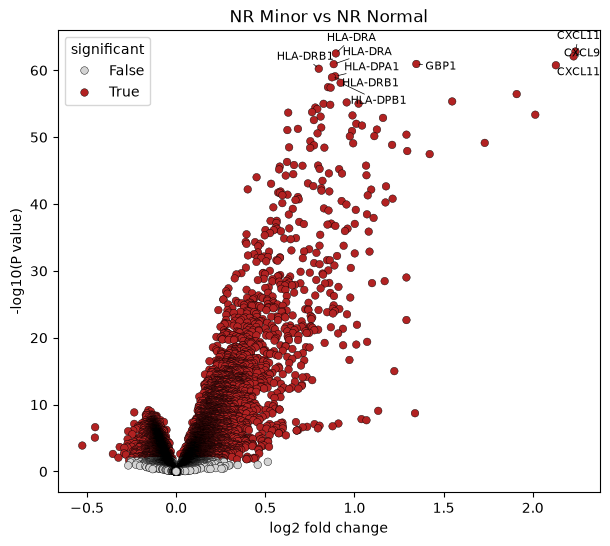

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from adjustText import adjust_text

res["neg_log10_p"] = -np.log10(res["P.Value"])  #Y-axis
res["significant"] = res["adj.P.Val"] < 0.05

top = res.nsmallest(10, "adj.P.Val")  ##Genes with top 10 lowest adj p values

fig, ax = plt.subplots(figsize = (7, 6))  #empty plot
sns.scatterplot(
    data=res, x = "logFC", y = "neg_log10_p", hue = "significant",
    palette={True: "firebrick", False: "lightgrey"},
    s = 30, edgecolor = "black", linewidth = 0.3, rasterized = True, ax = ax,
)

texts = [ax.text(r.logFC, r.neg_log10_p, r.gene, fontsize = 8) for r in top.itertuples()]
adjust_text(texts, ax = ax, arrowprops = dict(arrowstyle = "-", color = "black", lw = 0.5))

ax.set_xlabel("log2 fold change")
ax.set_ylabel("-log10(P value)")
ax.set_title(f"{g2} vs {g1}")
fig.savefig(f"../results/volcono_{g2}_vs_{g1}.png", dpi=150, bbox_inches = "tight")

4) Loop to compare NR Normal with everything else one by one

- pABMR vs NR Normal
- pTCMR vs NR Normal
- ABMR vs NR Normal
- TCMR vs NR Normal
- Mixed vs NR Normal


In [25]:
from itertools import combinations

groups = ["NR Normal", "NR Minor", "pABMR", "pTCMR", "ABMR", "TCMR", "Mixed"]
ref = "NR Normal"
others = [g for g in groups if g != ref]

results = {}

for g2 in others:
    sub = labels[labels[group_col].isin([ref, g2])]
    E = expr.loc[:, sub.index]
    design = dmatrix(f"~ C({group_col}, Treatment('{ref}'))", sub, return_type="dataframe")

    fit = pylimma.eBayes(pylimma.lmFit(E, design))
    res = pylimma.topTable(fit, coef=1, number=np.inf).set_index("gene")
    res.index.name = "probe"

    res["gene"] = res.index.map(symbol)                         # column -> Series
    res["gene"] = res["gene"].fillna(res.index.to_series())   # Series.fillna accepts a Series
    res["neg_log10_p"] = -np.log10(res["P.Value"])
    res["significant"] = res["adj.P.Val"] < 0.05

    name = f"{g2}_vs_{ref}"
    results[name] = res
    res.to_csv(f"../results/de_{name}.csv")
    print(name, "| n =", len(sub), "| significant probes:", res["significant"].sum())


NR Minor_vs_NR Normal | n = 821 | significant probes: 24530
pABMR_vs_NR Normal | n = 623 | significant probes: 33658
pTCMR_vs_NR Normal | n = 500 | significant probes: 29534
ABMR_vs_NR Normal | n = 641 | significant probes: 38593
TCMR_vs_NR Normal | n = 538 | significant probes: 40857
Mixed_vs_NR Normal | n = 475 | significant probes: 30078


5) Creating volcano plots for all the comparisons and putting it on a single figure

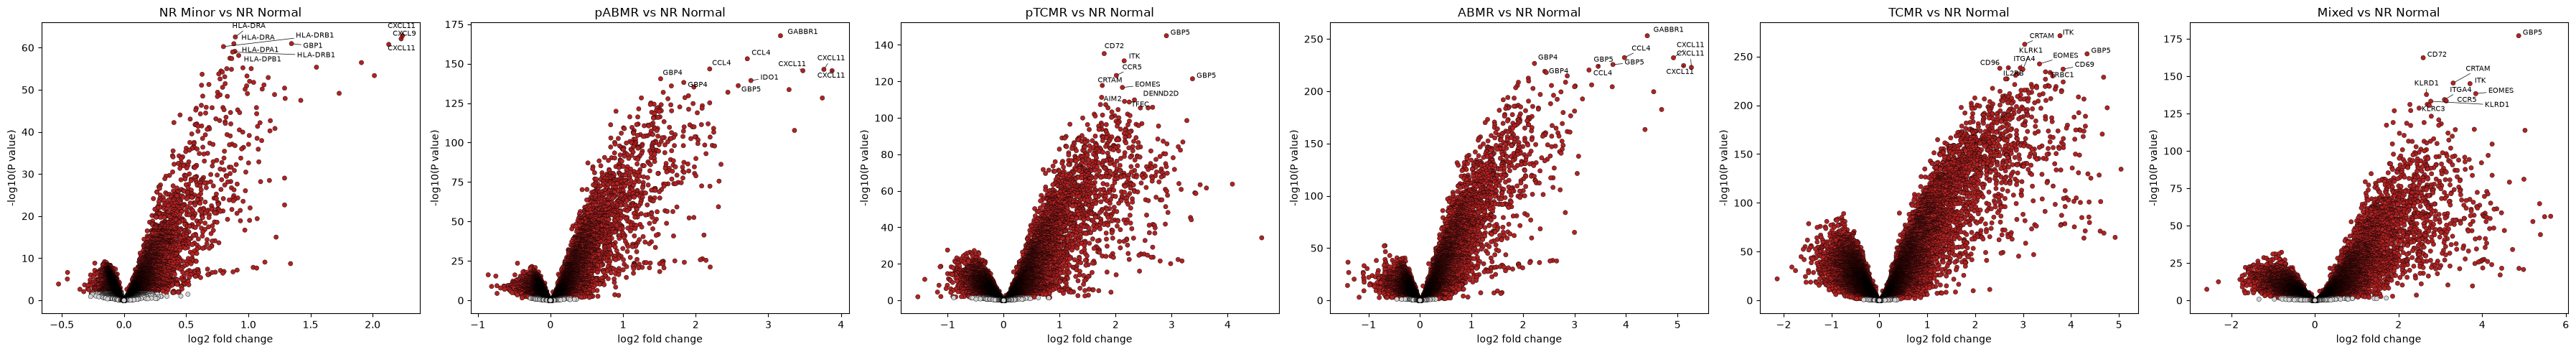

In [27]:
n = len(results)
fig, axes = plt.subplots(1, n, figsize=(6 * n, 5), squeeze=False)
axes = axes.ravel()                                   # 2D grid -> flat list of panels

for ax, (name, res) in zip(axes, results.items()):
    sns.scatterplot(data=res, x="logFC", y="neg_log10_p", hue="significant",
                    palette={True: "firebrick", False: "lightgrey"},
                    s=20, edgecolor="black", linewidth=0.3, rasterized=True,
                    legend=False, ax=ax)

    top = res.nsmallest(10, "adj.P.Val")
    texts = [ax.text(r.logFC, r.neg_log10_p, r.gene, fontsize=7) for r in top.itertuples()]
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="black", lw=0.5))

    ax.set_title(name.replace("_", " "))
    ax.set_xlabel("log2 fold change")
    ax.set_ylabel("-log10(P value)")

fig.tight_layout()
fig.savefig(f"../results/volcano_all_vs_{ref}.png", dpi=150, bbox_inches="tight")

In [34]:
fig.savefig("../figures/volcano_all_vs_ref.png", dpi=150, bbox_inches="tight")

top20 = pd.concat({name: r.nsmallest(20, "adj.P.Val")[["gene", "logFC", "adj.P.Val"]]
                   for name, r in results.items()})
top20.to_csv("../tables/de_top20_per_comparison.csv")